# Chapter 7 - Combining Different Models for Ensemble Learning

### Combinatorial argument
We compute the probability of the majority of the classifiers classifying wrong using the binomial distribution

In [44]:
from scipy.special import comb
import math

def ensemble_error(n_classifier, error):
    k_start = math.ceil(n_classifier / 2.) # We have a majority of errors for k_start or more
    probs = [comb(n_classifier, k) * error**k * (1-error)**(n_classifier - k) # Binomial distribution
             for k in range(k_start, n_classifier + 1)]
    return sum(probs) # Cummulative probability from k_start

ensemble_error(n_classifier=11, error=0.25)

np.float64(0.03432750701904297)

Back to presentation

## Implementing a simple majority vote classifier - Hard voting counts votes; soft voting averages confidence.


Load and prepare data

In [45]:
from sklearn import datasets
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.pipeline import Pipeline
from sklearn.ensemble import VotingClassifier

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

iris = datasets.load_iris()

# Use 2 classes and 2 features (same as your code)
X, y = iris.data[50:, [1, 2]], iris.target[50:]

le = LabelEncoder()
y = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.5,
    random_state=1,
    stratify=y
)

Define base classifiers

In [46]:
clf1 = LogisticRegression(solver='lbfgs', penalty='l2',
                          C=0.001, random_state=1)

clf2 = DecisionTreeClassifier(max_depth=1,
                              criterion='entropy',
                              random_state=0)

clf3 = KNeighborsClassifier(n_neighbors=1)

Pipelines

In [47]:
pipe1 = Pipeline([('sc', StandardScaler()), ('clf', clf1)])
pipe3 = Pipeline([('sc', StandardScaler()), ('clf', clf3)])

clf_labels = ['Logistic regression', 'Decision tree', 'KNN']

Evaluate individual classifiers

In [48]:
print('10-fold cross validation:\n')

for clf, label in zip([pipe1, clf2, pipe3], clf_labels):
    scores = cross_val_score(clf, X_train, y_train,
                             cv=10, scoring='roc_auc')
    print("ROC AUC: %0.2f (+/- %0.2f) [%s]"
          % (scores.mean(), scores.std(), label))

10-fold cross validation:

ROC AUC: 0.92 (+/- 0.15) [Logistic regression]
ROC AUC: 0.87 (+/- 0.18) [Decision tree]
ROC AUC: 0.85 (+/- 0.13) [KNN]


Hard voting (majority voting)

In [49]:
mv_clf = VotingClassifier(
    estimators=[('pipe1', pipe1), ('clf2', clf2), ('pipe3', pipe3)],
    voting='hard'
)

Evaluate hard voting

In [50]:
clf_labels_mv = clf_labels + ['Voting (hard)']
all_clf = [pipe1, clf2, pipe3, mv_clf]

for clf, label in zip(all_clf, clf_labels_mv):
    scores = cross_val_score(
        estimator=clf,
        X=X_train,
        y=y_train,
        cv=10,
        scoring='accuracy'
    )
    print("Accuracy: %0.2f (+/- %0.2f) [%s]"
          % (scores.mean(), scores.std(), label))

Accuracy: 0.44 (+/- 0.08) [Logistic regression]
Accuracy: 0.86 (+/- 0.20) [Decision tree]
Accuracy: 0.84 (+/- 0.15) [KNN]
Accuracy: 0.84 (+/- 0.20) [Voting (hard)]


Soft voting (probability-based)

In [51]:
mv_clf_soft = VotingClassifier(
    estimators=[('pipe1', pipe1), ('clf2', clf2), ('pipe3', pipe3)],
    voting='soft'
)

Evaluate soft voting

In [52]:
clf_labels_soft = clf_labels + ['Voting (soft)']
all_clf_soft = [pipe1, clf2, pipe3, mv_clf_soft]

for clf, label in zip(all_clf_soft, clf_labels_soft):
    scores = cross_val_score(clf, X_train, y_train,
                             cv=10, scoring='roc_auc')
    print("ROC AUC: %0.2f (+/- %0.2f) [%s]"
          % (scores.mean(), scores.std(), label))

ROC AUC: 0.92 (+/- 0.15) [Logistic regression]
ROC AUC: 0.87 (+/- 0.18) [Decision tree]
ROC AUC: 0.85 (+/- 0.13) [KNN]
ROC AUC: 0.98 (+/- 0.05) [Voting (soft)]


Soft voting with weights

In [53]:
mv_clf_soft_w = VotingClassifier(
    estimators=[('pipe1', pipe1), ('clf2', clf2), ('pipe3', pipe3)],
    voting='soft',
    weights=[0.1, 0.6, 0.3]
)

Evaluate Soft voting with weights

In [54]:
clf_labels_soft_w = clf_labels + ['Voting (soft, weighted)']
all_clf_soft_w = [pipe1, clf2, pipe3, mv_clf_soft_w]

for clf, label in zip(all_clf_soft_w, clf_labels_soft_w):
    scores = cross_val_score(
        estimator=clf,
        X=X_train,
        y=y_train,
        cv=10,
        scoring='roc_auc'
    )
    print("ROC AUC: %0.2f (+/- %0.2f) [%s]"
          % (scores.mean(), scores.std(), label))

ROC AUC: 0.92 (+/- 0.15) [Logistic regression]
ROC AUC: 0.87 (+/- 0.18) [Decision tree]
ROC AUC: 0.85 (+/- 0.13) [KNN]
ROC AUC: 0.98 (+/- 0.05) [Voting (soft, weighted)]


**Hard voting uses only the predicted class labels, so the final result is driven by the majority of classifiers. In this example, the weak logistic regression model is often outvoted by the stronger tree and KNN models, so the hard-voting accuracy stays close to those stronger base learners. Soft voting performs better because it uses predicted probabilities, not just labels, which preserves more information.**

ROC curves

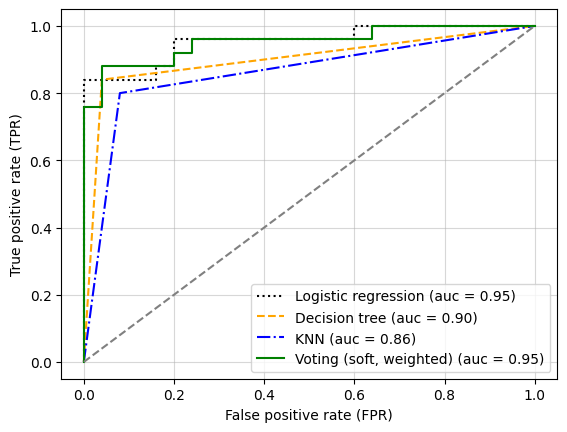

In [55]:
colors = ['black', 'orange', 'blue', 'green']
linestyles = [':', '--', '-.', '-']

all_clf_plot = [pipe1, clf2, pipe3, mv_clf_soft_w]
labels_plot = clf_labels + ['Voting (soft, weighted)']

for clf, label, clr, ls in zip(all_clf_plot, labels_plot, colors, linestyles):
    y_pred = clf.fit(X_train, y_train).predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_pred)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr,
             color=clr,
             linestyle=ls,
             label='%s (auc = %0.2f)' % (label, roc_auc))

plt.legend(loc='lower right')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')

plt.xlabel('False positive rate (FPR)')
plt.ylabel('True positive rate (TPR)')
plt.grid(alpha=0.5)
plt.show()

# Task:
# Remove or add one classifier.
# Then evaluate soft voting with 2 classifiers.
#
# Question:
# What is your observation?